# 01 · Experiment design: how I would test the next SMS campaign

> **Role of this notebook: theory and planning. Nothing here was launched.**
> The experiment analysed in notebook `02` was run by X5 Retail Group in 2019, not by me.
> This notebook shows how I *would* design the **next** test, using X5's control group only to
> obtain realistic numbers (baseline purchase rate and variance).
>
> Order of the project: **01 design** (this notebook) → *execution by X5, not part of this project* →
> **02 analysis** of X5's real results → **03 refinement** with CUPED on X5's data → recommendation.

## 1. Realistic inputs from X5's control group

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..") / "src"))
from ab_utils import aa_rejection_rate, mde_for_n, n_per_arm, n_with_cuped

DATA = Path("..") / "data_raw"
train_path = DATA / "uplift_train.csv.gz"
if not train_path.exists():
    raise FileNotFoundError(
        f"{train_path} not found. Download `uplift_train.csv.gz` from the Hugging Face dataset "
        "`pytorch-lifestream/retailhero-uplift` into the `data_raw/` folder (see README)."
    )

train = pd.read_csv(train_path)
control = train.loc[train["treatment_flg"] == 0, "target"].to_numpy()

In [2]:
p = control.mean()          # baseline purchase rate without SMS
variance = p * (1 - p)      # variance of a 0/1 outcome: this is what drives the sample size
print(f"Control customers: {len(control):,}")
print(f"Baseline purchase rate p = {p:.3f}")
print(f"Variance p(1-p)          = {variance:.3f}")

Control customers: 100,058
Baseline purchase rate p = 0.603
Variance p(1-p)          = 0.239


Why these two numbers matter: for a yes/no outcome the **variance is fixed by the baseline rate**.
A rate near 50 % is the noisiest possible outcome, so it needs the most customers to detect a given change.
A 60 % baseline is close to that worst case, which is why a small lift is hard to detect with certainty.

## 2. Design document (as I would hand it to a product manager)

**Decision to support:** should we keep sending the SMS campaign to this customer base?

**Hypotheses.** H0: the SMS has no effect on the purchase rate (difference = 0). H1: the SMS changes the purchase rate (two-sided).

**Primary metric:** purchase rate in the outcome window.

**Decision rule** (read once, after the planned 2 weeks and the planned sample; no interim peeking):

0. **Validity first.** If the randomisation checks fail (sample-ratio mismatch, covariate imbalance), do not read the effect; fix the assignment and rerun.
1. **Ship** if the 95 % confidence interval of the effect lies entirely above the break-even effect (1 pp under the assumptions in section 2) and no guardrail is harmed.
2. **Iterate** if the effect is positive and significant but the interval reaches below the break-even effect, or a guardrail is worse: the SMS works but may not pay off, so refine the message or the targeting.
3. **Stop** if the interval includes 0 or is negative: with the planned sample, any real effect is smaller than the MDE.

**Guardrail metrics** *(hypothetical, X5's data does not contain them)*:
- Average basket value: guards against the SMS pulling forward cheap purchases.
- SMS opt-out / complaint rate: guards against hurting the long-term relationship.

**Randomisation unit:** the customer (one assignment per `client_id`, 50/50), so a customer never sees both versions.

**Analysis plan:** difference in purchase rates with a 95 % confidence interval; randomisation checks first
(sample-ratio mismatch, covariate balance); one pre-registered primary metric; segment results labelled
exploratory. CUPED (section 5) is the planned variance-reduction step and is applied in notebook `03`.

### Sample size, minimum detectable effect and duration

In [3]:
# --- Economic assumptions (HYPOTHETICAL: X5's data has no costs or margins; edit freely) ---
SMS_COST = 0.05                   # euros per SMS sent
MARGIN_PER_PURCHASE = 5.00        # euros of margin on one incremental purchase (e.g. ~EUR 20 basket x 25 % margin)

ALPHA, POWER = 0.05, 0.80
BREAK_EVEN_EFFECT = SMS_COST / MARGIN_PER_PURCHASE   # lift (in purchase rate) at which the SMS exactly pays for itself
CHOSEN_MDE = BREAK_EVEN_EFFECT    # smallest lift worth detecting = the lift that makes the SMS profitable
WEEKLY_REACHABLE = 40_000         # ASSUMPTION: customers we can enrol per week (editable)
MIN_WEEKS = 2                     # at least two full weekly cycles, whatever the sample size says

n = n_per_arm(p, CHOSEN_MDE, ALPHA, POWER)
weeks = max(MIN_WEEKS, int(np.ceil(2 * n / WEEKLY_REACHABLE)))

print(f"Break-even effect = SMS cost / margin = {SMS_COST} / {MARGIN_PER_PURCHASE} = {BREAK_EVEN_EFFECT * 100:.1f} pp")
print(f"Detect {CHOSEN_MDE * 100:.1f} pp with alpha={ALPHA}, power={POWER:.0%}")
print(f"  customers per arm : {n:,}")
print(f"  customers in total: {2 * n:,}")
print(f"  duration          : {weeks} weeks (assuming {WEEKLY_REACHABLE:,} customers enrolled per week)")

# Sensitivity: the margin assumption is the least certain input, so show what happens if it is wrong
sens = pd.DataFrame({"margin per purchase (EUR)": [2.5, 5.0, 10.0]})
sens["break-even effect (pp)"] = (SMS_COST / sens["margin per purchase (EUR)"] * 100).round(2)
sens["customers per arm"] = [n_per_arm(p, SMS_COST / m, ALPHA, POWER) for m in sens["margin per purchase (EUR)"]]
sens

Break-even effect = SMS cost / margin = 0.05 / 5.0 = 1.0 pp
Detect 1.0 pp with alpha=0.05, power=80%
  customers per arm : 37,570
  customers in total: 75,140
  duration          : 2 weeks (assuming 40,000 customers enrolled per week)


,margin per purchase (EUR),break-even effect (pp),customers per arm
0,2.5,2.0,9393
1,5.0,1.0,37570
2,10.0,0.5,150280


**Why this minimum detectable effect (MDE)?** The MDE is a *business* choice, not a statistical one: it is the
smallest lift that would still make the campaign worth running. I derive it from the economics:

`break-even effect = cost per SMS / margin per incremental purchase`

Each SMS costs money for every customer, but only the *extra* purchases it causes bring margin. With the stated
(hypothetical) assumptions of EUR 0.05 per SMS and EUR 5 margin per incremental purchase, the SMS pays for itself
at a lift of 1 pp, so **1 pp is the MDE**. A smaller true effect would lose money even if it were real; a lift
we cannot detect is not worth chasing. The sensitivity table shows the main risk: the margin figure is the least
certain input, and a lower margin raises the break-even effect (and lowers the sample needed).

The cost of precision grows with 1/MDE², so choosing the MDE well matters.

*Cross-check:* notebook `02` uses the `statsmodels` arcsine method and gets about 37,400 per arm for the same
inputs, less than 1 % below the normal-approximation formula used here. Both are valid approximations.

## 3. Sample size against the effect we want to detect

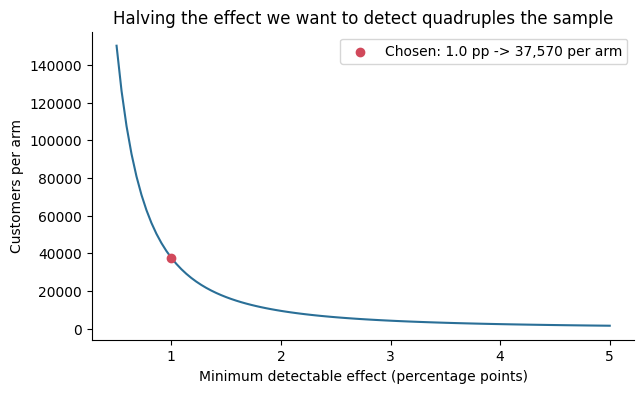

In [4]:
mdes = np.linspace(0.005, 0.05, 100)
sizes = [n_per_arm(p, m, ALPHA, POWER) for m in mdes]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mdes * 100, sizes, color="#2a6f97")
ax.scatter([CHOSEN_MDE * 100], [n], color="#d1495b", zorder=3, label=f"Chosen: {CHOSEN_MDE * 100:.1f} pp -> {n:,} per arm")
ax.set_xlabel("Minimum detectable effect (percentage points)")
ax.set_ylabel("Customers per arm")
ax.set_title("Halving the effect we want to detect quadruples the sample")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. Planned stopping rule: why we do not peek (A/A simulation)

An **A/A test** splits customers into two groups that receive the *same* treatment (here, nobody gets the SMS),
so any "significant" difference is a false positive. I reshuffle X5's real control outcomes into two random
halves and test them. If I test only once at the end, about 5 % of simulations should be flagged (that is what
alpha = 0.05 means). If I **look repeatedly and stop at the first significant result**, the rate climbs.

 1 look(s): false-positive rate = 5.3%
 2 look(s): false-positive rate = 8.8%
 5 look(s): false-positive rate = 15.2%
10 look(s): false-positive rate = 20.6%
20 look(s): false-positive rate = 26.3%


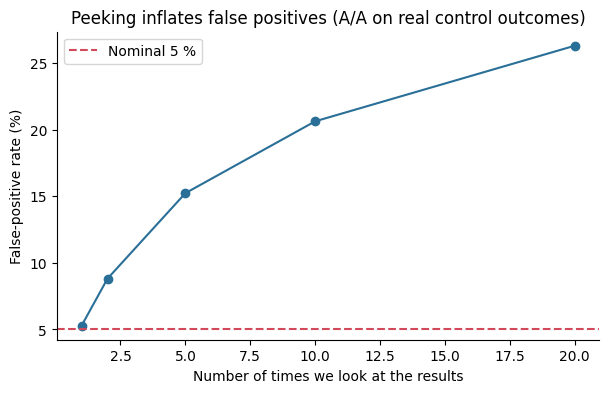

In [5]:
looks_list = [1, 2, 5, 10, 20]
rates = [aa_rejection_rate(control, n_sims=5000, looks=k, alpha=ALPHA, seed=0) for k in looks_list]

assert 0.04 <= rates[0] <= 0.06, f"One-look false-positive rate should be near 5 %, got {rates[0]:.3f}"

for k, r in zip(looks_list, rates):
    print(f"{k:>2} look(s): false-positive rate = {r:.1%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(looks_list, [r * 100 for r in rates], marker="o", color="#2a6f97")
ax.axhline(ALPHA * 100, color="#d1495b", linestyle="--", label="Nominal 5 %")
ax.set_xlabel("Number of times we look at the results")
ax.set_ylabel("False-positive rate (%)")
ax.set_title("Peeking inflates false positives (A/A on real control outcomes)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**What this means in practice.** Checking the dashboard daily and stopping when the p-value dips below 0.05 turns a
5 % error rate into a much larger one. Two honest options: (a) **fix the horizon** in advance (the sample size and
duration above) and read the result only at the end, or (b) use **sequential testing** methods designed for repeated
looks. Sequential methods are the natural next step; they are noted here as future work and not implemented.

## 5. CUPED in theory: getting the same precision with fewer customers

**CUPED** (Controlled-experiment Using Pre-Experiment Data) removes the part of the outcome that we could already
predict from the customer's *past* behaviour. Customers who bought a lot before will tend to buy again whatever we
send them; that habit is noise for the question "did the SMS change anything?".

For each customer, with `x` a pre-experiment measure (say, past spend):

`y_adjusted = y - theta * (x - mean(x))`, with `theta = cov(x, y) / var(x)`

**Why it does not bias the result.** `x` is measured *before* the test, so randomisation splits high-spenders
evenly across both arms: the treated and control groups have the same average `x`. Subtracting a term with equal
average in both groups leaves the *difference* between groups unchanged, but removes noise around it.
(Customers who already bought a lot are shared across the arms, not kept out of the treatment group.)

**How much it helps.** The variance shrinks by a factor `(1 - rho^2)`, where `rho` is the correlation between past
and future behaviour. The stronger the habit, the bigger the gain. Notebook `03` estimates `rho` on real data;
here is what different values would imply for our design:

In [6]:
rhos = [0.3, 0.5, 0.7]
table = pd.DataFrame(
    {
        "rho (illustrative)": rhos,
        "customers per arm": [n_with_cuped(n, r) for r in rhos],
    }
)
table["saving vs. no CUPED"] = (1 - table["customers per arm"] / n).map("{:.0%}".format)
table.style.hide(axis="index").set_caption(
    "Illustrative rho, not estimated from data. The real rho is estimated in notebook 03."
)

rho (illustrative),customers per arm,saving vs. no CUPED
0.300000,34189,9%
0.500000,28178,25%
0.700000,19161,49%


## 6. Summary of the plan

| Item | Choice |
|---|---|
| Unit / split | customer, 50/50 |
| Primary metric | purchase rate |
| MDE | break-even effect = SMS cost / margin (1 pp under the stated assumptions) |
| Sample | see section 2 (per arm and total) |
| Stopping rule | fixed horizon, no peeking |
| Variance reduction | CUPED (theory here, application in notebook `03`) |
| Guardrails | basket value, opt-out rate (hypothetical) |

Next: notebook `02` analyses what X5's real experiment found.